# mesh2geo walkthrough: melt-pool mesh → BSE phase space

This notebook runs the whole chain on the FLOW-3D cutout `block.stl`:

1. Settings
2. Look at the mesh: units and size
3. Convert it to penRed geometry with `mesh_to_geo`
4. Check the geometry before spending CPU on it
5. Make the materials at density / K
6. Build the config
7. Run penRed
8. Pull out the backscattered electrons (BSE) and save them for the ray tracer
9. Plot trajectories over the surface
10. View the same trajectories in a 3D half-section

Everything penRed writes goes into `run/`, so the other files in this folder are left alone.

**Frame.** penRed coordinates. The beam travels along +z. `mesh_to_geo` shifts the mesh so its highest point is at z = 0, with the metal at z > 0. The BSE slab sits 2–3 µm above the highest point (z = −3 to −2 µm). The figures plot height = −z, so the beam comes in from the top.

```
height = −z
  +3 µm  ┌─────────── BSE slab (nearvac, detector 1) ───────────┐
  +2 µm  └──────────────────────────────────────────────────────┘
  +1 µm                       ▼ source
   0     ┄┄┄┄┄┄┄┄┄┄┄┄┄┄┄ highest point of the mesh ┄┄┄┄┄┄┄┄┄┄┄┄┄┄┄
             ○  ○  powder  ○    \  keyhole  /    ○  ○   ○
         ▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔\          /▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔▔
                                  \________/      metal below
```

## 1. Settings

Everything you'd normally change is here. `mesh2geo.py` lives in `particlev2`, so that folder goes on the import path.

In [1]:
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import pyPenred

TOOLS = Path(r"E:\Code\EPBF_Twin\testing\particlev2")  # mesh2geo.py and the base config.in
HERE = Path(r"E:\Code\EPBF_Twin\testing\meltpool")
RUN = HERE / "run"                                     # penRed writes into the working directory
sys.path.insert(0, str(TOOLS))
from mesh2geo import UNIT_TO_CM, mesh_to_geo, read_geo, read_mesh

MESH = HERE / "block.stl"
UNITS = "m"                   # units of the numbers in the mesh file: m, cm, mm or um
METAL = ("Ti64", 4.43, [(22, 0.90), (13, 0.06), (23, 0.04)])  # name, g/cm^3, (Z, mass fraction); as ti64creater.py
# METAL = ("Cu", 8.96, [(29, 1.0)])
K = 1e4                       # length scale factor, see step 3
SOURCE_UM = (0.0, 0.0, -1.0)  # beam origin (x, y, z) in um, penRed frame; z between -2 and 0 is just below the slab
CONE_DEG = 5.0                # beam half-angle
NHIST = 1e5
THREADS = os.cpu_count()
UM = 1e-4                     # 1 um in cm

RUN.mkdir(exist_ok=True)
os.chdir(RUN)

## 2. Look at the mesh

Check the units first. The header says µm, but the coordinates only reach 0.0006, so the numbers are in metres (0.0006 m = 600 µm) and `UNITS = "m"`.

`Z_TOP_UM` is the highest point in the mesh's own frame. penRed puts it at z = 0, and step 8 uses it to hand the BSE back in the mesh frame.

In [2]:
v_in, f_in = read_mesh(MESH)
print(MESH.read_bytes()[:80].decode(errors="ignore").strip())
print(f"{len(f_in)} triangles, {len(v_in)} vertices")
print("min", v_in.min(axis=0), " max", v_in.max(axis=0))
print("size (um):", np.ptp(v_in, axis=0) * UNIT_TO_CM[UNITS] / UM)

Z_TOP_UM = v_in[:, 2].max() * UNIT_TO_CM[UNITS] / UM
print(f"highest point: z = {Z_TOP_UM:.2f} um")

flow3d_python cutout (-600.0, 600.0, -600.0, 600.0, -600.0, 300.0) um
225634 triangles, 111777 vertices
min [-0.0006 -0.0006 -0.0006]  max [0.0006     0.0006     0.00015544]
size (um): [1200.000057   1200.000057    755.43677667]
highest point: z = 155.44 um


## 3. Convert the mesh

`mesh_to_geo` writes a penRed `MESH_BODY` file with three bodies. Their order is the `IBODY` index in the track output:

| IBODY | body | material | what it is |
|---|---|---|---|
| 0 | `meltpool` | 1, `METAL` | the mesh (an open surface would get side walls and a flat base `depth_um` below its lowest point) |
| 1 | `bse_detector` | 2, nearvac | a slab `gap_um` = 2 µm above the highest point, `thickness_um` = 1 µm thick, over the whole footprint |
| 2 | `world` | 0, vacuum | a box `pad_um` = 5 µm bigger than everything |

It returns the `geometry` section of the config, with `kdet` and `dsmax` keyed by body name.

What the printout tells you for this file:

- **31 triangles were wound the wrong way.** That's common in marching-cubes exports. They're flipped so the whole surface faces out of the metal.
- **One pore.** A 16-triangle closed shell sits inside the metal near (−420, −85) µm, about 8 µm across. It's kept and faces into the pore, so penRed treats it as vacuum.
- **Missed crossings.** penRed skips a triangle when `|edge1 · (dir × edge2)| < 1e-8`. That tolerance is a fixed number in cm², sized for cm-scale parts. µm-scale triangles get skipped at shallow angles, and electrons can fly straight through the surface. `scale=K` multiplies every length in the file by K. Dividing every density by K (step 5) leaves the physics unchanged, because transport depends only on density × length. This mesh's ~10 µm triangles would miss only 0.04 % with K = 1, but a finer mesh of the same pool would not be so lucky, and scaling costs nothing at run time.

In [3]:
geometry = mesh_to_geo(MESH, "meltpool.geo", units=UNITS, scale=K)
geometry

Wrote meltpool.geo: 225634 triangles in the melt pool
  fixed the winding of 31 triangles that faced the wrong way
  2 separate shells, 1 of them pores inside the metal
  melt pool  x [-600.00, 600.00]  y [-600.00, 600.00]  z [0, 755.44] um  (z = depth below the highest point)
  BSE slab   z [-3.00, -2.00] um
  Put the source between the slab and the surface (z between -2.00 and 0 um), or above the slab (z between -8.00 and -3.00 um).
  Lengths in the file are x10000 (the positions above are physical um): divide material densities by 10000, multiply source and tally positions by 10000, divide PSF/track positions by 10000.
  penRed will miss about 0.00% of surface crossings (triangle size vs its 1e-8 cm^2 tolerance)


{'type': 'MESH_BODY',
 'input-file': 'meltpool.geo',
 'kdet': {'bse_detector': 1},
 'dsmax': {'meltpool': 1.0}}

## 4. Check the geometry

`read_geo` loads the file back, dividing by K to give physical lengths. Below are two sections through the beam axis. Check three things: the metal sits under the slab, the source is in the gap between them, and the beam cone lands where you want it. A point source with a 5° half-angle spreads to about ±40 µm by the keyhole floor, which is almost 470 µm below the source.

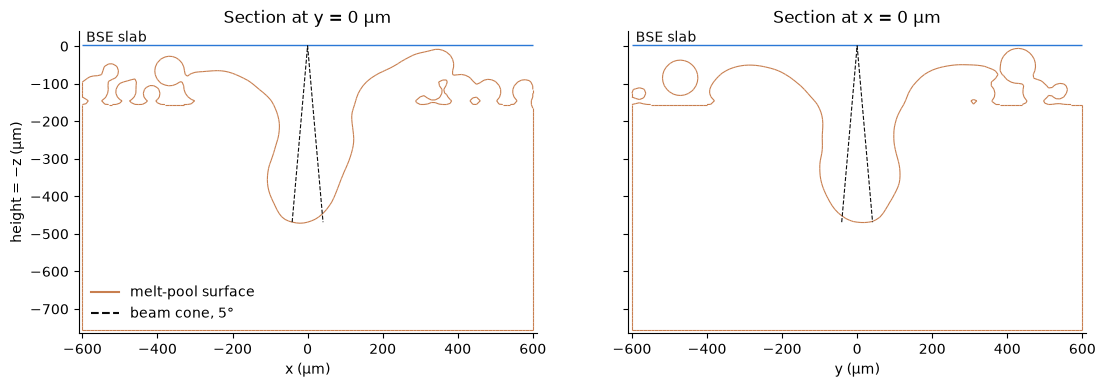

beam axis meets the surface 470 um below the source; spot radius there ≈ 41 um


In [4]:
bodies = read_geo("meltpool.geo", scale=K)  # {name: (vertices, faces)}, physical cm
v, f = bodies["meltpool"]
v = v / UM                                   # um
slab_lo, slab_hi = bodies["bse_detector"][0].min(axis=0) / UM, bodies["bse_detector"][0].max(axis=0) / UM


def section(v, f, axis, value):
    """Segments (n, 2, 3) where the plane v[:, axis] = value cuts the triangles."""
    a = v[f]
    b = np.roll(a, -1, axis=1)               # the three edges: 0-1, 1-2, 2-0
    sa, sb = a[:, :, axis] - value, b[:, :, axis] - value
    cut = (sa >= 0) != (sb >= 0)            # a vertex exactly on the plane counts as above it
    with np.errstate(divide="ignore", invalid="ignore"):
        p = a + (b - a) * (sa / (sa - sb))[:, :, None]
    two = cut.sum(axis=1) == 2
    return p[two][cut[two]].reshape(-1, 2, 3)


def first_hit(seg, along, s):
    """Depth of the first surface straight below position s, from a section's segments."""
    a, b = seg[:, 0], seg[:, 1]
    with np.errstate(divide="ignore", invalid="ignore"):
        t = (s - a[:, along]) / (b[:, along] - a[:, along])
    ok = (t >= 0) & (t <= 1)
    return (a[ok, 2] + t[ok] * (b[ok, 2] - a[ok, 2])).min()


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, cut_axis, along in [(axes[0], 1, 0), (axes[1], 0, 1)]:
    seg = section(v, f, cut_axis, SOURCE_UM[cut_axis])
    ax.add_collection(LineCollection(seg[:, :, [along, 2]] * [1, -1], color="#c87f4f", lw=0.8))
    ax.add_patch(plt.Rectangle((slab_lo[along], -slab_hi[2]), slab_hi[along] - slab_lo[along],
                               slab_hi[2] - slab_lo[2], color="#2a78d6"))
    s, h = SOURCE_UM[along], -SOURCE_UM[2]
    hit = first_hit(seg, along, s)                           # where the beam axis meets the surface
    spread = (hit + h) * np.tan(np.radians(CONE_DEG))
    ax.plot([s - spread, s, s + spread], [-hit, h, -hit], color="#0b0b0b", lw=0.8, ls="--")
    ax.set(xlim=(slab_lo[along] - 10, slab_hi[along] + 10), ylim=(-v[:, 2].max() - 10, 40), aspect="equal",
           xlabel=f"{'xy'[along]} (µm)",
           title=f"Section at {'xy'[cut_axis]} = {SOURCE_UM[cut_axis]:g} µm")
    ax.text(slab_lo[along] + 10, 12, "BSE slab", color="#0b0b0b")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("height = −z (µm)")
axes[0].legend(handles=[plt.Line2D([], [], color="#c87f4f", label="melt-pool surface"),
                        plt.Line2D([], [], color="#0b0b0b", ls="--", label=f"beam cone, {CONE_DEG:g}°")],
               loc="lower left", frameon=False)
plt.show()
print(f"beam axis meets the surface {hit + h:.0f} um below the source; spot radius there ≈ {spread:.0f} um")

## 5. Materials at density / K

These are the metal from `METAL` and the same near-vacuum as `nearvac.mat`, each with its density divided by K.

In [5]:
name, density, composition = METAL
air = [(6, 0.000124), (7, 0.755268), (8, 0.231781), (18, 0.012827)]  # mass fractions, as in nearvac.mat
pyPenred.simulation.materials.create(name, density / K, composition, f"{name}_scaled.mat")
pyPenred.simulation.materials.create("nearvac", 1e-10 / K, air, "nearvac_scaled.mat")

## 6. Config

Start from the quadric setup in `particlev2/config.in` and change only what the mesh needs:

- `geometry`: what `mesh_to_geo` returned
- material 1: renamed from `cu` to the metal, pointing at its scaled file (the transport settings stay); material 2: the scaled nearvac
- source position: × K (directions are unchanged)
- the two dose-grid tallies take extents in cm, so they're dropped here. To keep them, multiply their extents by K. The dose they report is then low by K², because each bin holds K² times the mass.

The PSF, energy spectra and angular tallies need no change.

In [6]:
config = pyPenred.readConfigFile(str(TOOLS / "config.in"))
config["geometry"] = geometry
config["materials"][name] = config["materials"].pop("cu")
config["materials"][name]["filename"] = f"{name}_scaled.mat"
config["materials"]["nearvac"]["filename"] = "nearvac_scaled.mat"

source = config["sources"]["generic"]["source1"]
for axis, value in zip("xyz", SOURCE_UM):
    source["spatial"]["position"][axis] = value * UM * K
source["direction"]["alpha"] = CONE_DEG
source["nhist"] = NHIST

for name in ("cylDoseDistrib", "SpatialDoseDistrib"):
    config["tallies"].pop(name)
config["simulation"]["threads"] = THREADS

pyPenred.writeConfigFile("modified.in", config)
source

{'direction': {'alpha': 5.0, 'phi': 0.0, 'theta': 0.0, 'type': 'CONE'},
 'energy': {'energy': 40000.0, 'type': 'MONOENERGETIC'},
 'kpar': 'electron',
 'nhist': 100000.0,
 'spatial': {'position': {'x': 0.0, 'y': 0.0, 'z': -1.0}, 'type': 'POINT'}}

## 7. Run

With this 225k-triangle mesh, penRed takes about 50 s to load the geometry, then runs about 260 histories per second per thread. On 64 threads, 1e5 histories take about a minute in total. penRed prints a progress block per thread, and the same goes to `run/simulation.log`.

In [7]:
t0 = time.time()
pyPenred.runFromFile("modified.in")
print(f"{NHIST:.0e} histories on {THREADS} threads: {time.time() - t0:.0f} s")

Configuration set

Simulation started

Thread 0: Source source1: Simulated 1563/1563 histories in the current source.
   Simulation speed         :     2.60500E+02 hist/s
   Estimated time remaining :     0.00000E+00 s

Thread 1: Source source1: Simulated 1563/1563 histories in the current source.
   Simulation speed         :     2.60500E+02 hist/s
   Estimated time remaining :     0.00000E+00 s

Thread 2: Source source1: Simulated 1563/1563 histories in the current source.
   Simulation speed         :     2.60500E+02 hist/s
   Estimated time remaining :     0.00000E+00 s

Thread 3: Source source1: Simulated 1563/1563 histories in the current source.
   Simulation speed         :     2.60500E+02 hist/s
   Estimated time remaining :     0.00000E+00 s

Thread 4: Source source1: Simulated 1563/1563 histories in the current source.
   Simulation speed         :     2.60500E+02 hist/s
   Estimated time remaining :     0.00000E+00 s

Thread 5: Source source1: Simulated 1563/1563 histories 

## 8. BSE phase space

The PSF holds every particle entering the slab. A BSE is an electron entering it moving away from the surface (W < 0). The same rule drops the primaries if you put the source above the slab.

For the ray tracer, the BSE go out in the mesh's own frame, with +z up as in the STL:

- positions divided by K
- z = `Z_TOP_UM` − Z
- the direction's z component flipped (w = −W)

Every BSE starts on the slab's lower face, 2 µm above the highest point, and flies in a straight line from there.

In [8]:
pyPenred.psf.psf2ascii("psf-merged.dat", "psf-electrons.txt")
columns = ["DHIST", "KPAR", "E", "X", "Y", "Z", "U", "V", "W", "WGHT", "PAGE",
           "ILB1", "ILB2", "ILB3", "ILB4", "ILB5"]
psf = pd.read_csv("psf-electrons.txt", sep=r"\s+", comment="#", header=None, names=columns)
bse = psf[(psf["KPAR"] == 0) & (psf["W"] < 0)]

print(f"BSE per primary: {len(bse) / NHIST:.4f} ± {np.sqrt(len(bse)) / NHIST:.4f}")
print(f"mean BSE energy: {bse['E'].mean() / 1e3:.1f} keV")

# Handoff for the ray tracer: mesh frame (+z up), um and keV, one row per BSE
out = pd.DataFrame({
    "E_keV": bse["E"] / 1e3,
    "x_um": bse["X"] / K / UM,
    "y_um": bse["Y"] / K / UM,
    "z_um": Z_TOP_UM - bse["Z"] / K / UM,
    "u": bse["U"], "v": bse["V"], "w": -bse["W"],
    "weight": bse["WGHT"],
})
out.to_csv("bse_phase_space.csv", index=False)
out.describe().loc[["mean", "min", "max"]]

BSE per primary: 0.0582 ± 0.0008
mean BSE energy: 22.2 keV


,E_keV,x_um,y_um,z_um,u,v,w,weight
mean,22.197687,24.195119,4.538279,157.436748,0.03601,-0.00142,0.900601,1.0
min,1.003300,-499.530000,-476.840000,157.436748,-0.96902,-0.93661,0.212650,1.0
max,40.000000,348.800000,349.890000,157.436748,0.87897,0.90178,0.999990,1.0


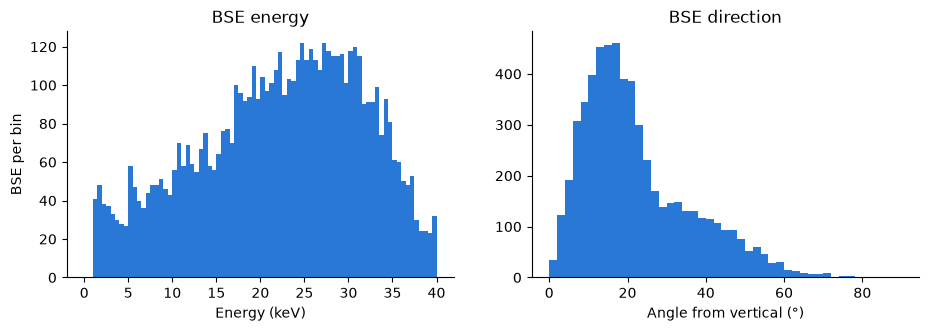

In [9]:
theta = np.degrees(np.arccos(out["w"]))  # angle from straight up
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2))
a.hist(out["E_keV"], bins=80, range=(0, 40), color="#2a78d6")
a.set(xlabel="Energy (keV)", ylabel="BSE per bin", title="BSE energy")
b.hist(theta, bins=45, range=(0, 90), color="#2a78d6")
b.set(xlabel="Angle from vertical (°)", title="BSE direction")
for ax in (a, b):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 9. Trajectories over the surface

The TRACK tally writes the first 25 histories of each thread to `track-th*-electron-tracks.dat`. Each block is one particle, with columns E X Y Z U V W WGHT IBODY MAT PAGE ILB1..5. IBODY 1 is the slab, and ILB1 = 1 marks a primary. The BSE rule is the same as in step 8: the track reaches the slab moving away from the surface.

The tracks are 3D, projected onto the x–z plane. The surface line is only the y = 0 section, so a track can appear to cross it.

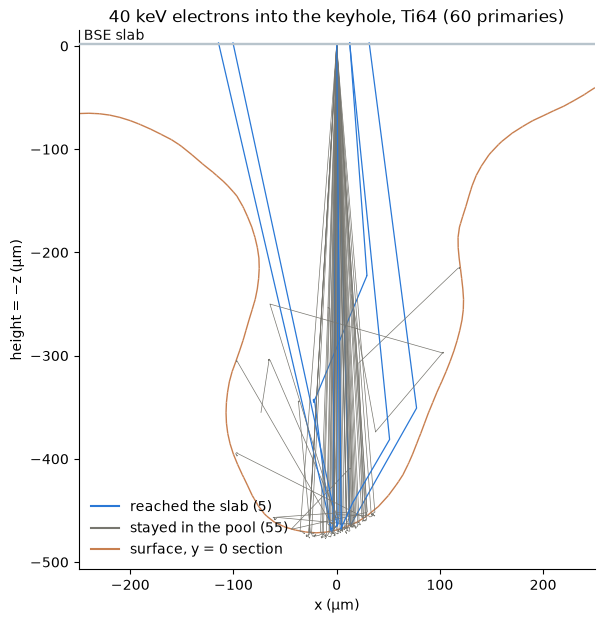

In [10]:
N_TRACKS = 60  # primaries to draw

tracks = []
for path in sorted(Path().glob("track-th*-electron-tracks.dat")):
    for block in path.read_text().split("\n\n\n"):
        rows = [l.split() for l in block.splitlines() if l.strip() and not l.startswith("#")]
        if rows and rows[0][11] == "1":
            tracks.append(np.array(rows, float))
    if len(tracks) >= N_TRACKS:
        break
tracks = tracks[:N_TRACKS]

fig, ax = plt.subplots(figsize=(8, 7))
seg = section(v, f, 1, SOURCE_UM[1])
ax.add_collection(LineCollection(seg[:, :, [0, 2]] * [1, -1], color="#c87f4f", lw=1.0, zorder=1))
ax.add_patch(plt.Rectangle((slab_lo[0], -slab_hi[2]), slab_hi[0] - slab_lo[0], slab_hi[2] - slab_lo[2],
                           color="#b8c4cc", zorder=3))

n_bse = 0
for t in tracks:
    bse_track = ((t[:, 8] == 1) & (t[:, 6] < 0)).any()  # reached the slab moving away from the surface
    n_bse += bse_track
    ax.plot(t[:, 1] / K / UM, -t[:, 3] / K / UM, zorder=2,
            color="#2a78d6" if bse_track else "#77766f", lw=0.9 if bse_track else 0.5)

floor = max(t[:, 3].max() for t in tracks) / K / UM
ax.set(xlim=(SOURCE_UM[0] - 250, SOURCE_UM[0] + 250), ylim=(-floor - 30, 15), aspect="equal",
       xlabel="x (µm)", ylabel="height = −z (µm)",
       title=f"40 keV electrons into the keyhole, {METAL[0]} ({len(tracks)} primaries)")
ax.text(SOURCE_UM[0] - 245, 6, "BSE slab", color="#0b0b0b")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[plt.Line2D([], [], color="#2a78d6", label=f"reached the slab ({n_bse})"),
                   plt.Line2D([], [], color="#77766f", label=f"stayed in the pool ({len(tracks) - n_bse})"),
                   plt.Line2D([], [], color="#c87f4f", label="surface, y = 0 section")],
          loc="lower left", frameon=False)
fig.savefig("bse_trajectories_mesh.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. 3D half-section view

The same tracks in 3D, drawn like a CAD section view. The melt pool is cut through the beam axis and the front half is removed, so you look into the keyhole:

- the light face is the cut through the metal
- the shaded surface is the keyhole's back wall
- the translucent plate is the BSE slab

`L` sets the size of the view around the beam.

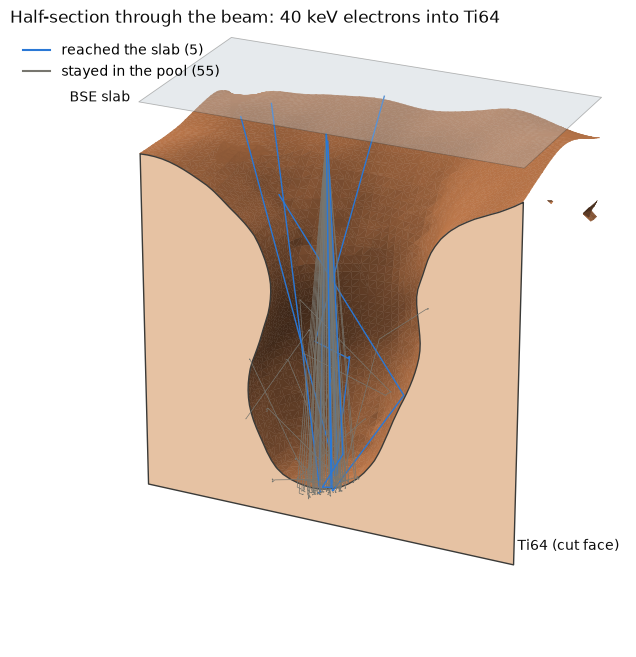

In [11]:
from matplotlib.colors import LightSource
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

L = 250.0  # half-width of the view around the beam, um
x0, y0 = SOURCE_UM[:2]
y_cut = y0 + 0.01     # just off the beam axis: FLOW-3D vertices sit exactly on grid planes such as y = 0
bottom = -floor - 40  # crop the solid a little below the keyhole floor


def surface_line(seg):
    """Chain section segments end to end; return the one starting furthest left, as (n, 2)."""
    nbr = {}
    for a, b in np.round(seg, 6).tolist():
        nbr.setdefault(tuple(a), []).append(tuple(b))
        nbr.setdefault(tuple(b), []).append(tuple(a))
    line = [min((p for p in nbr if len(nbr[p]) == 1), key=lambda p: p[0])]
    while len(line) == 1 or len(nbr[line[-1]]) == 2:
        line.append(next(q for q in nbr[line[-1]] if len(line) == 1 or q != line[-2]))
    return np.array(line)


# Plot coordinates are (x, y, height = -z) in um. Reversing the corner order keeps the
# normals facing out of the metal after the z flip, which the shading relies on.
tri = v[f][:, ::-1] * [1, 1, -1]
c = tri.mean(axis=1)
tri = tri[(np.abs(c[:, 0] - x0) < L) & (c[:, 1] > y_cut) & (c[:, 1] < y0 + L) & (c[:, 2] > bottom)]  # back half

# Cut face at y_cut: the metal between the surface line and the bottom of the view
seg = section(v, f, 1, y_cut)[:, :, [0, 2]] * [1, -1]
seg = seg[(np.abs(seg[:, :, 0] - x0) < L).all(axis=1) & (seg[:, :, 1] > bottom).all(axis=1)]
line = surface_line(seg)
face = np.r_[[(x0 - L, line[0, 1])], line, [(x0 + L, line[-1, 1]), (x0 + L, bottom), (x0 - L, bottom)]]
face = np.c_[face[:, 0], np.full(len(face), y_cut), face[:, 1]]

h = -slab_hi[2]  # lower face of the BSE slab
slab = [[(x0 - L, y0, h), (x0 + L, y0, h), (x0 + L, y0 + L, h), (x0 - L, y0 + L, h)]]

fig = plt.figure(figsize=(9, 8), facecolor="white")
ax = fig.add_subplot(projection="3d", computed_zorder=False)
ax.add_collection3d(Poly3DCollection(tri, facecolors="#c87f4f", edgecolors="#c87f4f", linewidths=0.3,
                                     shade=True, lightsource=LightSource(azdeg=-60, altdeg=40), zorder=1))
ax.add_collection3d(Poly3DCollection([face], facecolor="#e6c2a3", edgecolor="#3a3a38", linewidth=1.0, zorder=2))
for t in tracks:
    xyz = t[:, 1:4] / K / UM * [1, 1, -1]
    xyz[(np.abs(xyz[:, 0] - x0) > L) | (np.abs(xyz[:, 1] - y0) > L)] = np.nan  # clip to the view
    reached = ((t[:, 8] == 1) & (t[:, 6] < 0)).any()
    ax.plot(*xyz.T, zorder=3, color="#2a78d6" if reached else "#77766f", lw=1.0 if reached else 0.5)
ax.add_collection3d(Poly3DCollection(slab, facecolor="#b8c4cc", alpha=0.35, edgecolor="#3a3a38",
                                     linewidth=0.6, zorder=4))

ax.text(x0 - L, y0, h, "BSE slab  ", ha="right", color="#0b0b0b")
ax.text(x0 + L, y0, bottom + 20, f" {METAL[0]} (cut face)", color="#0b0b0b")
ax.set(xlim=(x0 - L, x0 + L), ylim=(y0 - L, y0 + L), zlim=(bottom, 10))
ax.set_box_aspect((2 * L, 2 * L, 10 - bottom), zoom=1.15)
ax.view_init(elev=25, azim=-65)
ax.set_axis_off()
ax.legend(handles=[plt.Line2D([], [], color="#2a78d6", lw=1.5, label=f"reached the slab ({n_bse})"),
                   plt.Line2D([], [], color="#77766f", lw=1.5, label=f"stayed in the pool ({len(tracks) - n_bse})")],
          loc="upper left", frameon=False)
ax.set_title(f"Half-section through the beam: 40 keV electrons into {METAL[0]}", loc="left", color="#0b0b0b")
fig.savefig("bse_trajectories_3d.png", dpi=200, bbox_inches="tight")
plt.show()

## Using another mesh

- Set `MESH` and `UNITS` in step 1, and check the units against the bounding box in step 2.
- If the free surface doesn't face +z, pass `up=` to `mesh_to_geo` (`"+y"`, `"-x"`, …). `Z_TOP_UM` and the w flip in step 8 assume +z.
- Open surfaces such as height maps work too. The tool closes them with walls and a base, but they need a single outer edge and a roughly rectangular or circular outline.
- The mesh must be manifold: every edge shared by at most two triangles. Winding errors and pores are handled; anything else stops with an error, so repair those in MeshLab or Blender.
- Move the beam with `SOURCE_UM`. x and y can be anywhere over the footprint; z must be between −2 and 0 µm, or above the slab.
- For production statistics, raise `NHIST`. At ~16,000 histories/s on 64 threads, 1e7 histories take about 10 minutes for this mesh.